### 1. Data Generation and Preprocessing
We will generate synthetic daily page-view traffic for 5 articles over 400 days, introduce some missing values to demonstrate handling them, and construct chronological sequences.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

np.random.seed(42)
torch.manual_seed(42)

dates = pd.date_range(start="2022-01-01", periods=400, freq="D")
articles = [f"Article_{i+1}" for i in range(5)]

data_dict = {"Date": dates}
for art in articles:

    base = np.linspace(100, 300, 400)
    seasonality = 50 * np.sin(2 * np.pi * np.arange(400) / 7) + 30 * np.sin(2 * np.pi * np.arange(400) / 30)
    noise = np.random.normal(0, 15, 400)
    views = base + seasonality + noise

    nan_mask = np.random.rand(400) < 0.05
    views[nan_mask] = np.nan
    data_dict[art] = np.clip(views, a_min=0, a_max=None)

df = pd.DataFrame(data_dict)
df.set_index("Date", inplace=True)

print("Initial DataFrame with missing values:")
display(df.head())
print("Missing value counts per article:")
print(df.isnull().sum())

Initial DataFrame with missing values:


,Article_1,Article_2,Article_3,Article_4,Article_5
Date,,,,,
2022-01-01,107.450712,NaN,97.493174,96.489702,111.523108
2022-01-02,143.756213,120.177652,150.068877,152.825554,149.061126
2022-01-03,171.666329,141.728220,158.220634,176.761019,169.575031
2022-01-04,163.676952,151.980465,164.941688,139.692239,199.725070
2022-01-05,99.092870,105.168152,109.969795,97.807457,71.343476


Missing value counts per article:
Article_1    17
Article_2    18
Article_3    23
Article_4    17
Article_5    18
dtype: int64


### Imputing Missing Values & Scaling
We will fill any missing values using forward-fill (and backward-fill if any remains) to preserve the temporal continuity, then normalize the views using `MinMaxScaler`.

In [4]:

df = df.ffill().bfill()

scalers = {}
scaled_data = {}
for col in df.columns:
    scaler = MinMaxScaler()
    scaled_data[col] = scaler.fit_transform(df[[col]].values)
    scalers[col] = scaler

print("Data preprocessing and scaling complete.")

Data preprocessing and scaling complete.


### 2. Generating Chronological Sequences
We will use a sliding window approach (e.g., lookback of 14 days) to create sequences for training the sequential model.

In [5]:
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:(i + seq_length)]
        y = data[i + seq_length]
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 14
X_dict, y_dict = {}, {}

for col in df.columns:
    X_dict[col], y_dict[col] = create_sequences(scaled_data[col], seq_length)

test_size = 30

X_train_dict, X_test_dict = {}, {}
y_train_dict, y_test_dict = {}, {}

for col in df.columns:
    X_train_dict[col] = X_dict[col][:-test_size]
    y_train_dict[col] = y_dict[col][:-test_size]
    X_test_dict[col] = X_dict[col][-test_size:]
    y_test_dict[col] = y_dict[col][-test_size:]

print(f"Sequence shape (X_train for Article_1): {X_train_dict['Article_1'].shape}")
print(f"Sequence shape (y_train for Article_1): {y_train_dict['Article_1'].shape}")

Sequence shape (X_train for Article_1): (356, 14, 1)
Sequence shape (y_train for Article_1): (356, 1)


### 3. Model Definition and Training
We select an **LSTM (Long Short-Term Memory)** network because it is well-suited for capturing both short-term dependencies (weekly patterns) and long-term trends over time.

In [6]:
class LSTMModel(nn.Module):
    def __init__(self, input_dim=1, hidden_dim=64, num_layers=2, output_dim=1):
        super(LSTMModel, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).to(x.device)
        out, _ = self.lstm(x, (h0, c0))
        out = self.fc(out[:, -1, :])
        return out

models = {}
criterion = nn.MSELoss()
epochs = 150

for col in df.columns:
    print(f"Training LSTM model for {col}...")
    model = LSTMModel()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

    X_t = torch.tensor(X_train_dict[col], dtype=torch.float32)
    y_t = torch.tensor(y_train_dict[col], dtype=torch.float32)

    model.train()
    for epoch in range(epochs):
        optimizer.zero_grad()
        outputs = model(X_t)
        loss = criterion(outputs, y_t)
        loss.backward()
        optimizer.step()

    models[col] = model
print("Training completed for all articles!")

Training LSTM model for Article_1...
Training LSTM model for Article_2...
Training LSTM model for Article_3...
Training LSTM model for Article_4...
Training LSTM model for Article_5...
Training completed for all articles!


### 4. Evaluation and Visualization
We evaluate predictions using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) on our test set, then visualize actual vs. predicted values.

Article_1 -> MAE: 39.18 | RMSE: 49.25
Article_2 -> MAE: 37.52 | RMSE: 43.58
Article_3 -> MAE: 36.77 | RMSE: 45.20
Article_4 -> MAE: 32.01 | RMSE: 38.50
Article_5 -> MAE: 29.94 | RMSE: 37.72


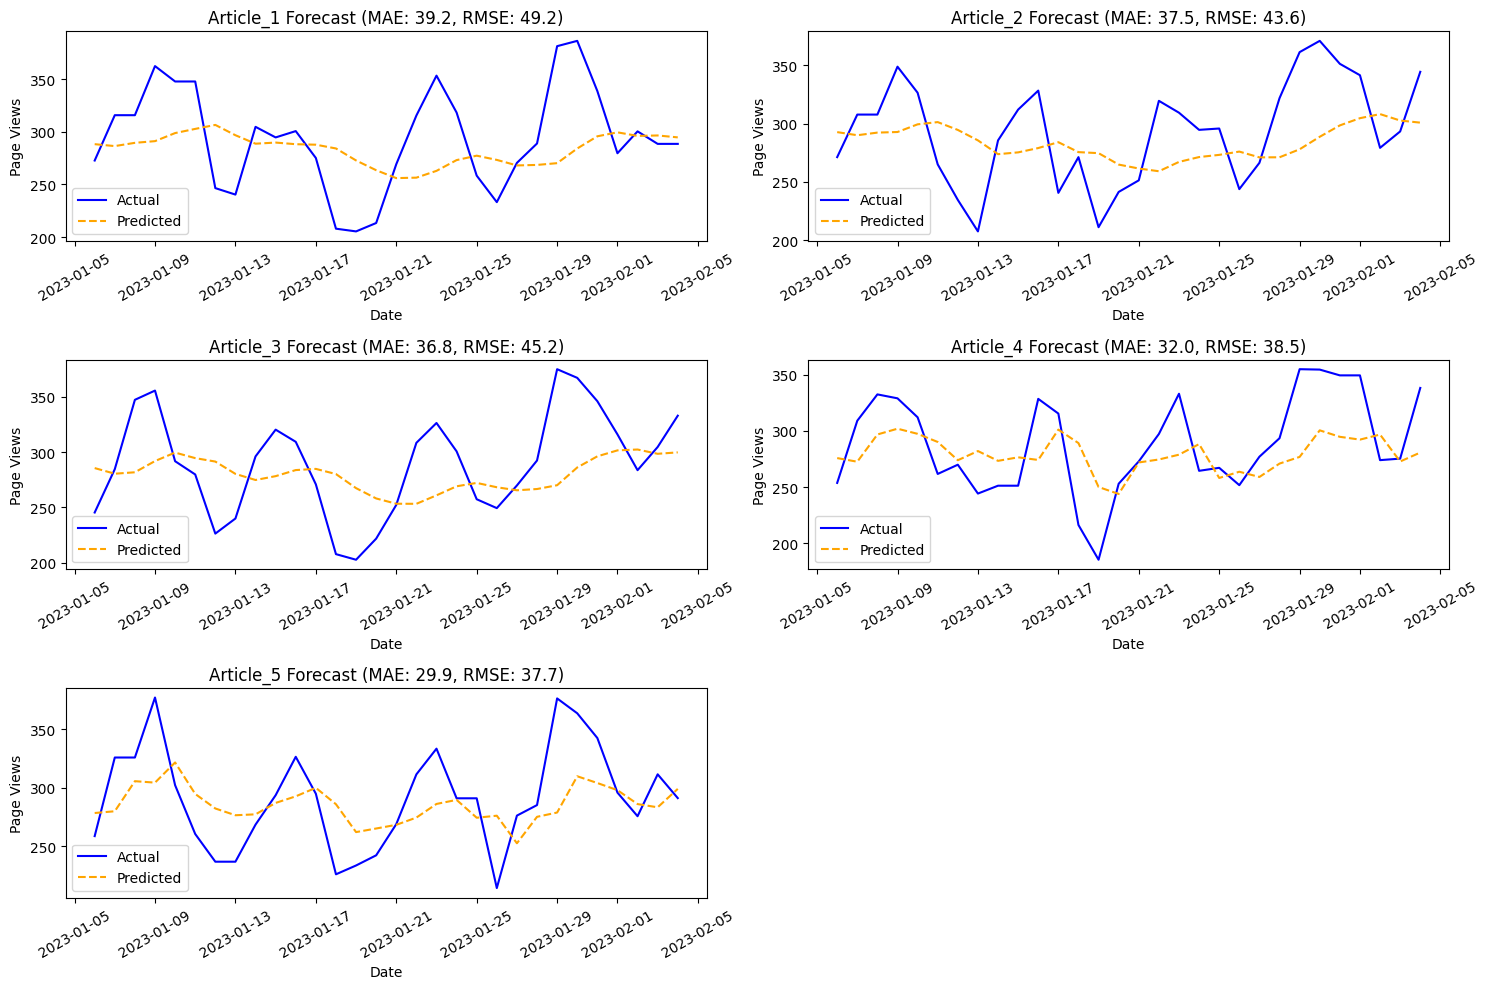

In [7]:
plt.figure(figsize=(15, 10))

for idx, col in enumerate(df.columns):
    model = models[col]
    model.eval()

    X_te = torch.tensor(X_test_dict[col], dtype=torch.float32)
    with torch.no_grad():
        pred = model(X_te).numpy()

    actual = scalers[col].inverse_transform(y_test_dict[col])
    predicted = scalers[col].inverse_transform(pred)

    mae = mean_absolute_error(actual, predicted)
    rmse = root_mean_squared_error(actual, predicted)

    print(f"{col} -> MAE: {mae:.2f} | RMSE: {rmse:.2f}")

    plt.subplot(3, 2, idx + 1)
    test_dates = df.index[-test_size:]
    plt.plot(test_dates, actual, label="Actual", color="blue")
    plt.plot(test_dates, predicted, label="Predicted", color="orange", linestyle="--")
    plt.title(f"{col} Forecast (MAE: {mae:.1f}, RMSE: {rmse:.1f})")
    plt.xlabel("Date")
    plt.ylabel("Page Views")
    plt.legend()
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### 5. Demonstrating Predictions on Unseen Future Dates (Out-of-Sample Forecasting)
Since we do not have actual future records, we use the recursive (autoregressive) method: feed the model's own predictions back as inputs to forecast subsequent steps.

In [9]:
future_steps = 10
future_predictions = {}

last_date = df.index[-1]
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=future_steps, freq='D')

for col in df.columns:
    model = models[col]
    model.eval()

    current_window = list(scaled_data[col][-seq_length:].flatten())
    preds = []

    for _ in range(future_steps):

        input_tensor = torch.tensor([current_window], dtype=torch.float32).unsqueeze(-1)

        with torch.no_grad():
            pred_scaled = model(input_tensor).item()

        preds.append(pred_scaled)
        current_window.append(pred_scaled)
        current_window.pop(0)

    future_predictions[col] = scalers[col].inverse_transform(np.array(preds).reshape(-1, 1)).flatten()

future_df = pd.DataFrame(future_predictions, index=future_dates)
print("Predicted page views for unseen future dates:")
display(future_df)

Predicted page views for unseen future dates:


,Article_1,Article_2,Article_3,Article_4,Article_5
2023-02-05,292.692940,306.414642,304.548022,306.871766,293.052831
2023-02-06,291.046498,303.883443,302.012967,290.486170,293.323751
2023-02-07,289.004745,302.251917,300.231218,285.084183,292.346857
2023-02-08,287.380029,300.813685,298.834342,285.331798,292.145055
2023-02-09,286.399504,299.443685,298.020582,286.905515,292.163469
2023-02-10,285.686133,298.689972,297.340081,288.685010,294.257385
2023-02-11,284.627852,297.735393,296.441572,289.593395,295.200140
2023-02-12,283.418457,296.219561,295.299613,289.666088,295.401899
2023-02-13,281.323357,294.288308,293.200767,287.897384,292.754635
2023-02-14,279.198153,292.251585,291.164036,285.395301,289.549075
